In [1]:
from dotenv import load_dotenv
load_dotenv()

from langchain.chat_models import init_chat_model
llm=init_chat_model("groq:openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.5.4', 'langchain': '1.3.15'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000024C66111010>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000024C66111D30>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [2]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages:Annotated[list,add_messages]

## Langgraph Chatbot With Tool

In [3]:
pip install langchain-tavily

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
from langchain_tavily import TavilySearch

#Tavily is an AI-focused web search engine.
#In LangChain/LangGraph, you can give your agent a tool that allows it to search the web for up-to-date information.

tool=TavilySearch(max_results=2) # max_results tells Tavily how many search results it should return from a web search.
tool.invoke("Who is the chief minister of TamilNadu 2026")

{'query': 'Who is the chief minister of TamilNadu 2026',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'title': 'T.N. government formation highlights: TVK chief Vijay to be sworn in as Chief Minister on May 10 - The Hindu',
   'url': 'https://www.thehindu.com/elections/tamil-nadu-assembly/tamil-nadu-government-formation-live-updates-cpi-cpim-vck-dmk-aiadmk-ammk-tvk-alliance-parties-may-9-2026/article70958001.ece',
   'content': 'Tamilaga Vettri Kazhagam (TVK) president C. Joseph Vijay will be sworn in as the Chief Minister of Tamil Nadu on Sunday (May 10, 2026), putting an end to almost six decades of alternating rule by the State’s two dominant Dravidian parties—DMK and AIADMK. Tamil Nadu Governor Rajendra Vishwanath Arlekar on Saturday (May 9, 2026) appointed Mr. Vijay as Chief Minister-designate after he secured the support of 120 MLAs-elect in the 234-member House. [...] Outgoing Tamil Nadu Chief Minister and DMK chief M. K. Stalin on Saturday (May 9, 

In [5]:
## custom tool
def addition(a:int,b:int)-> int:
    """Add two numbers"""
    return a+b

In [6]:
tools=[tool,addition]
llm_with_tool=llm.bind_tools(tools)
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.5.4', 'langchain': '1.3.15'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000024C66111010>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000024C66111D30>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and

In [15]:
# StateGraph (ReAct flow)
from langgraph.graph import StateGraph,START # Builds the LangGraph workflow; START → graph starting point; END → graph stopping point.
from langgraph.prebuilt import ToolNode # Allocates node to tool and Executes the tools (e.g., Tavily search) called by the LLM.
from langgraph.prebuilt import tools_condition # Checks whether the LLM wants to call a tool and routes the graph accordingly.

# tools_condition checks whether the latest AI message has a tool call; 
# if yes, it routes to tools, otherwise it returns the special __end__ route, which stops the graph.

# Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

#Graph
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

#Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

graph=builder.compile()

# You don't need to explicitly write:builder.add_edge(..., END)
# because tools_condition handles the routing to the end when there is no tool call.

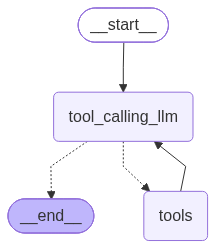

In [8]:
from IPython.display import Image,display
display(Image(graph.get_graph().draw_mermaid_png()))

In [9]:
response=graph.invoke({"messages":"what is gold price in bse today"})
response

{'messages': [HumanMessage(content='what is gold price in bse today', additional_kwargs={}, response_metadata={}, id='d8ff584b-0cd7-4436-b5bc-a0d5caa20f7b'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'User asks: "what is gold price in bse today". Need current gold price. We should use the search tool.', 'tool_calls': [{'id': 'fc_557b510a-f166-468a-8b9e-0d995bbb8ed3', 'function': {'arguments': '{"query":"gold price BSE today","search_depth":"basic","topic":"news"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 64, 'prompt_tokens': 343, 'total_tokens': 407, 'completion_time': 0.078777794, 'completion_tokens_details': {'reasoning_tokens': 26}, 'prompt_time': 0.017879786, 'prompt_tokens_details': None, 'queue_time': 0.30669875, 'total_time': 0.09665758}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_37c9245f64', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'mod

In [10]:
response["messages"][-1].content

'**Gold price (BSE\u202f—\u202fDomestic market, 24\u202fSep\u202f2026)**  \n\n| Item | Price |\n|------|-------|\n| **Gold (per 10\u202fgrams)** | **₹1,40,540** |\n| **Approx. per gram** | ₹14,054 |\n\n*The figure is the prevailing spot price quoted by BSE‑listed gold dealers on the day of the market close. Prices are typically reported per 10\u202fgrams in India, so the above value is the price for a 10‑gram piece of gold.*\n\n**Source**\n\n- BusinessToday – “Gold Rate Today in Greater Mumbai 24th September\u202f2026” (₹1,40,540 per 10\u202fgrams)【2†L1-L4】.\n\n> *Note:* The price can vary slightly between different exchanges (e.g., New\u202fDelhi, Mumbai) and between spot and futures contracts. The figure above reflects the most recent domestic spot rate reported by BSE‑linked dealers.'

In [11]:
for m in response["messages"]:
    m.pretty_print() 

# pretty_print() is used to display a LangChain/LangGraph message in a clean, readable format.

================================ Human Message =================================

what is gold price in bse today
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_557b510a-f166-468a-8b9e-0d995bbb8ed3)
 Call ID: fc_557b510a-f166-468a-8b9e-0d995bbb8ed3
  Args:
    query: gold price BSE today
    search_depth: basic
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "gold price BSE today", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://timesofindia.indiatimes.com/business/india-business/gold-price-prediction-today-india-where-is-gold-silver-rate-headed-on-july-15-2026-mcx-gold-futures-outlook-us-iran-war-middle-east-tensions/articleshow/132406893.cms", "title": "Gold price prediction today: Where are gold & silver headed? Check July 15, 2026 outlook - The Times of India", "content": "Gold price prediction toda

In [12]:
response=graph.invoke({"messages":"what is 5 added by 2"})
response["messages"][-1].content

'7'

In [13]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

what is 5 added by 2
================================== Ai Message ==================================
Tool Calls:
  addition (fc_57393c80-59a4-48c7-a12f-cc7d111d0236)
 Call ID: fc_57393c80-59a4-48c7-a12f-cc7d111d0236
  Args:
    a: 5
    b: 2
================================= Tool Message =================================
Name: addition

7
================================== Ai Message ==================================

7


In [14]:
response=graph.invoke({"messages":"Give me the recent ai news and add 5 by 2 "})
for m in response['messages']:
    m.pretty_print()

# The  graph ends immediately after Tavily, instead of returning to the LLM and call the addition tool.
# in this case we didn't added the condition edge so the second message is ignored (Add 5 by 10)

================================ Human Message =================================

Give me the recent ai news and add 5 by 2 
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_2660c33f-262d-46fe-a76b-6703e998c3a7)
 Call ID: fc_2660c33f-262d-46fe-a76b-6703e998c3a7
  Args:
    query: latest AI news
    search_depth: advanced
    time_range: week
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.cnbc.com/2026/09/18/microsoft-ai-ceo-openais-latest-ai-revelation-a-serious-situation.html", "title": "Microsoft AI CEO: OpenAI's latest AI revelation a 'serious situation'", "content": "Microsoft AI CEO Mustafa Suleyman pressed for the need for artificial intelligence models to stay aligned to humanity's interests after OpenAI disclosed more incidents

## LangGraph General Steps

Whenever you're creating a LangGraph, think:

1. **Define State**
   
2. **Define Node Functions**
   
3. **Add Nodes**
   
4. **Add Edges**
   
5. **Add Conditional Edges (if needed)**
   
6. **Compile the Graph**
   
7. **Invoke / Stream the Graph**

# What is ReAct Agent in AI?

**ReAct** stands for **Reasoning + Acting**.

A ReAct agent is an AI agent architecture where the LLM:

1. Thinks about what to do.
2. Takes an action using a tool.
3. Observes the result.
4. Decides the next step.

Instead of answering immediately, the AI follows an iterative process to solve complex problems.

---

## ReAct Loop

The ReAct loop consists of three main stages:

### 1. Thought (Reasoning)

The LLM analyzes the problem and decides what information or action is needed.

### 2. Action

The agent calls a tool, such as a calculator, database, API, or search engine.

### 3. Observation

The agent receives the tool's result and uses it to determine what to do next.

This loop repeats until the agent has enough information to provide a final answer.

**ReAct Flow:**

Reason → Act → Observe → Repeat → Answer

---

## Real-World Example

Imagine you ask an AI agent:

> "What is the current weather in Chennai, and should I carry an umbrella?"

The agent might follow this process:

| Step | Process |
|---|---|
| **Thought** | "I need the current weather information for Chennai." |
| **Action** | Call a weather API. |
| **Observation** | API returns: 80% chance of rain. |
| **Thought** | "There is a high chance of rain, so I should recommend carrying an umbrella." |
| **Final Answer** | "Yes, carry an umbrella. There is an 80% chance of rain in Chennai." |

The important part is that the AI **used a tool, observed the result, and adapted its response.**

---

## ReAct vs Normal LLM

| Feature | Normal LLM | ReAct Agent |
|---|---|---|
| **Reasoning** | Generates an answer based on available context | Reasons about what to do next |
| **Tool Usage** | May not use tools | Can call tools dynamically |
| **External Information** | Limited to provided context or connected capabilities | Retrieves information through tools |
| **Multi-step Tasks** | Can explain steps | Can execute steps iteratively |

---
